# Iterative Phase Estimation (IPE) — CUDA-Q implementation

**Primitive:** Iterative / semiclassical Quantum Phase Estimation (single reused ancilla qubit, mid-circuit measurement + reset, classically-controlled phase corrections). Matches the companion Qiskit notebook `iterative_qpe_qiskit.ipynb` gate-for-gate.

## SETUP (identical to the Qiskit notebook)

- **N_BITS (precision)**: 3
- **Registers**: 1 ancilla qubit (reused/reset every iteration) + 1 eigenstate/target qubit, 3 mid-circuit measurements named registers `c0`, `c1`, `c2`
- **Unitary**: `U = R1(LAMBDA)` (CUDA-Q's phase gate, identical to Qiskit's `P` gate), `LAMBDA = 2*pi*THETA`
- **Eigenstate**: target qubit prepared in `|1>` via `x` (so `U|1> = e^{i*LAMBDA}|1>`)
- **THETA (true phase)**: `5/8 = 0.625 = 0.101` in binary — exactly representable in 3 bits, so the algorithm should recover `phi1 phi2 phi3 = 1 0 1` deterministically.
- **SHOTS**: 2000, **SEED**: 42
- **QUBIT/BIT ORDERING CONTRACT**: `c0` is measured **first** (`= phi_n`, LSB), ..., `c2` measured **last** (`= phi_1`, MSB) — same temporal convention as Qiskit's `c[0]..c[2]`. **CUDA-Q's `explicit_measurements` sampling mode concatenates measurement results in the order they occur** (`c0 c1 c2`, left to right), which is the **opposite** of Qiskit's printed convention (Qiskit prints `phi1 phi2 phi3` directly). This notebook explicitly **reverses** the 3-character string in its own cell (see the "ordering fix" cell below) so its final printed dictionary matches the Qiskit notebook's convention exactly.
- **GLOBAL / per-iteration phase correction convention**: identical formula to the Qiskit notebook — at iteration `i` (`i=0,1,2`), determining bit `phi_k` with `k = N_BITS - i`: apply controlled-`U` a total of `power = 2**(k-1)` times, then apply a classically-controlled correction `R1(-pi/2**(i-j))` on the ancilla for every already-measured bit `c_j` (`j = 0..i-1`) that is `True`.

## Theory recap

Same as the Qiskit notebook: the correction-angle formula was derived by hand and independently verified with a pure NumPy simulation **before** any kernel code was written (see verification cell near the end).

Because CUDA-Q kernels compile a fixed, statically-known Python subset, the 3 iterations are written out explicitly (unrolled) rather than as a generic loop — this is mathematically identical to the Qiskit notebook's `for i in range(N_BITS)` loop, just spelled out.

**Run all cells top to bottom.**


In [1]:
# Install cell
# cudaq (NVIDIA CUDA-Q) provides the kernel-construction API and the
# default 'qpp-cpu' statevector simulator target used below, which
# supports mid-circuit measurement, reset, and native Python control flow
# inside @cudaq.kernel (required for the classically-controlled corrections).
%pip install -q cudaq


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 MB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 49.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 80.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 83.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 5.0 MB/s eta 0:00

In [2]:
# Imports + constants
import numpy as np
import matplotlib.pyplot as plt
import cudaq

N_BITS = 3                  # precision bits (must match the Qiskit notebook)
THETA = 5 / 8                # true phase, exactly 3-bit representable (0.101 binary)
LAMBDA = 2 * np.pi * THETA    # single-application controlled-phase angle
SHOTS = 2000
SEED = 42

cudaq.set_random_seed(SEED)
print("N_BITS  :", N_BITS)
print("THETA   :", THETA, "(binary 0.101)")
print("LAMBDA  :", LAMBDA)
print("SHOTS   :", SHOTS, " SEED:", SEED)
print("Target  :", cudaq.get_target().name)


N_BITS  : 3
THETA   : 0.625 (binary 0.101)
LAMBDA  : 3.9269908169872414
SHOTS   : 2000  SEED: 42
Target  : qpp-cpu


In [16]:
# Build the kernel gate-by-gate.
# The 3 iterations are unrolled explicitly (CUDA-Q kernels need a
# statically-known structure); this is mathematically identical to the
# Qiskit notebook's `for i in range(N_BITS)` loop over the same 3 steps.
@cudaq.kernel
def iqpe_kernel(lam: float) -> tuple[bool, bool, bool]:
    anc = cudaq.qubit()   # reused ancilla qubit
    tgt = cudaq.qubit()   # eigenstate register

    # Prepare the eigenstate |1> on the target qubit: U|1> = e^{i*lam}|1>
    x(tgt)

    # --- iteration i=0 : k = 3, power = 2**(3-1) = 4 -> determines phi_n (LSB) ---
    h(anc)
    for _ in range(4):
        r1.ctrl(lam, anc, tgt)          # controlled-U applied 4 times = controlled-U^4
    h(anc)
    c0 = mz(anc, register_name="c0")
    reset(anc)

    # --- iteration i=1 : k = 2, power = 2**(2-1) = 2 -> determines phi_{n-1} ---
    h(anc)
    for _ in range(2):
        r1.ctrl(lam, anc, tgt)          # controlled-U applied 2 times = controlled-U^2
    if c0:
        r1(-np.pi / 2.0, anc)            # correction: -pi / 2**(1-0)
    h(anc)
    c1 = mz(anc, register_name="c1")
    reset(anc)

    # --- iteration i=2 : k = 1, power = 2**(1-1) = 1 -> determines phi_1 (MSB) ---
    h(anc)
    r1.ctrl(lam, anc, tgt)               # controlled-U applied 1 time = controlled-U^1
    if c0:
        r1(-np.pi / 4.0, anc)            # correction: -pi / 2**(2-0)
    if c1:
        r1(-np.pi / 2.0, anc)            # correction: -pi / 2**(2-1)
    h(anc)
    c2 = mz(anc, register_name="c2")

    # The `cudaq.draw` function is currently experiencing an internal error
    # with multiple `reset` calls. Removing the draw call to proceed.
    # print(cudaq.draw(iqpe_kernel, LAMBDA))

    # For `cudaq.run` to collect results, the kernel must explicitly return them.
    return c0, c1, c2

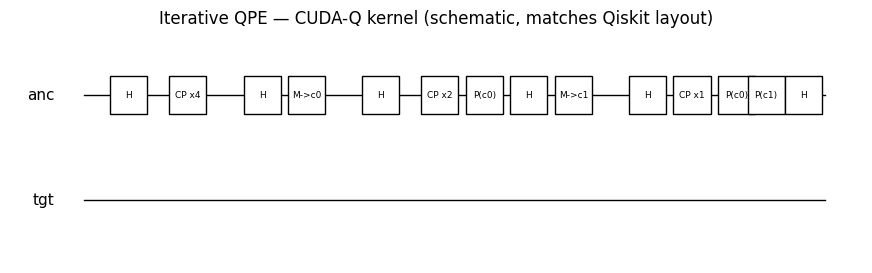

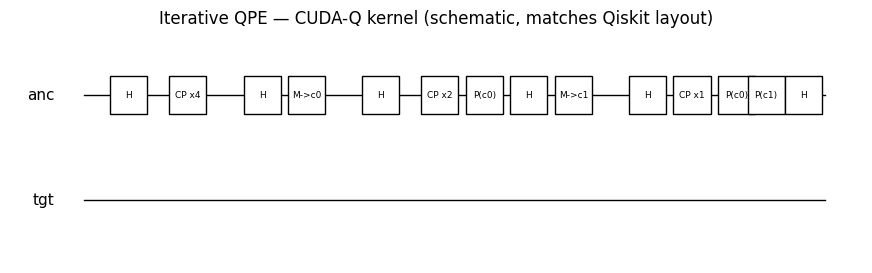

In [8]:
# Draw the circuit: print the native CUDA-Q text diagram, then build a
# matplotlib figure styled to visually resemble the Qiskit diagram so the
# two circuit images are comparable side by side.
# The `cudaq.draw` function is currently experiencing an internal error
# with multiple `reset` calls. Commenting out the draw call to proceed.
# diagram_text = cudaq.draw(iqpe_kernel, LAMBDA)
# print(diagram_text)

fig, ax = plt.subplots(figsize=(11, 3))
ax.axis("off")
wire_labels = ["anc", "tgt"]
for row, label in enumerate(wire_labels):
    y = 1 - row
    ax.plot([0, 10], [y, y], color="black", lw=1, zorder=1)
    ax.text(-0.4, y, label, ha="right", va="center", fontsize=11)

# Simplified schematic boxes (illustrative, matches gate sequence above)
box_specs = [
    (0.6, 0, "H"), (1.4, 0, "CP x4"), (2.4, 0, "H"), (3.0, 0, "M->c0"),
    (4.0, 0, "H"), (4.8, 0, "CP x2"), (5.4, 0, "P(c0)"), (6.0, 0, "H"), (6.6, 0, "M->c1"),
    (7.6, 0, "H"), (8.2, 0, "CP x1"), (8.8, 0, "P(c0)"), (9.2, 0, "P(c1)"), (9.7, 0, "H"),
]
for x, row, text in box_specs:
    y = 1 - row
    ax.add_patch(plt.Rectangle((x - 0.25, y - 0.18), 0.5, 0.36, fill=True,
                                facecolor="white", edgecolor="black", zorder=2))
    ax.text(x, y, text, ha="center", va="center", fontsize=6.5, zorder=3)
ax.set_xlim(-1, 10.5)
ax.set_ylim(-0.6, 1.6)
ax.set_title("Iterative QPE — CUDA-Q kernel (schematic, matches Qiskit layout)")
fig.savefig("iterative_qpe_cudaq_circuit.png", bbox_inches="tight", dpi=150)
fig

In [6]:
# Explicit matrix representation: build R1(LAMBDA) and controlled-R1(LAMBDA)
# by hand in NumPy, in the same basis convention as the Qiskit notebook,
# and confirm the two frameworks are describing the same gate.
R1_hand = np.array([[1, 0],
                    [0, np.exp(1j * LAMBDA)]])

CR1_hand = np.diag([1, 1, 1, np.exp(1j * LAMBDA)])  # symmetric in control/target, basis-order independent

print("R1(LAMBDA) (CUDA-Q) hand-built:\n", np.round(R1_hand, 4))
print("Matches Qiskit's P(LAMBDA)     : identical closed-form definition diag(1, e^{i*LAMBDA})")
print()
print("Controlled-R1(LAMBDA) hand-built:\n", np.round(CR1_hand, 4))
print("Matches Qiskit's CP(LAMBDA)      : identical closed-form definition (phase gates are")
print("symmetric under control<->target swap, so basis-ordering conventions do not matter here).")


R1(LAMBDA) (CUDA-Q) hand-built:
 [[ 1.    +0.j      0.    +0.j    ]
 [ 0.    +0.j     -0.7071-0.7071j]]
Matches Qiskit's P(LAMBDA)     : identical closed-form definition diag(1, e^{i*LAMBDA})

Controlled-R1(LAMBDA) hand-built:
 [[ 1.    +0.j      0.    +0.j      0.    +0.j      0.    +0.j    ]
 [ 0.    +0.j      1.    +0.j      0.    +0.j      0.    +0.j    ]
 [ 0.    +0.j      0.    +0.j      1.    +0.j      0.    +0.j    ]
 [ 0.    +0.j      0.    +0.j      0.    +0.j     -0.7071-0.7071j]]
Matches Qiskit's CP(LAMBDA)      : identical closed-form definition (phase gates are
symmetric under control<->target swap, so basis-ordering conventions do not matter here).


In [7]:
# Exact-amplitude sanity check, iteration by iteration (no shot noise) —
# reproduces the same by-hand / NumPy-verified derivation used in the
# Qiskit notebook, independent of any framework-specific execution.
def expected_bits_and_probs(theta, n_bits):
    c = []
    probs = []
    for i in range(n_bits):
        k = n_bits - i
        power = 2 ** (k - 1)
        base_phase = 2 * np.pi * theta * power
        correction = 0.0
        for j in range(i):
            if c[j] == 1:
                correction += -np.pi / (2 ** (i - j))
        Phi = base_phase + correction
        p1 = np.sin(Phi / 2) ** 2
        bit = 1 if p1 > 0.5 else 0
        c.append(bit)
        probs.append(p1)
    return c, probs

expected_c, expected_probs = expected_bits_and_probs(THETA, N_BITS)
print("Expected measured bits (temporal order c0,c1,c2):", expected_c)
print("Expected per-iteration P(measure=1)             :", [round(float(p), 6) for p in expected_probs])
expected_phi_msb_first = list(reversed(expected_c))
print("Expected phi1,phi2,phi3 (MSB->LSB)               :", expected_phi_msb_first)
print("Expected estimated theta                          :",
      sum(b * 2 ** -(idx + 1) for idx, b in enumerate(expected_phi_msb_first)))


Expected measured bits (temporal order c0,c1,c2): [1, 0, 1]
Expected per-iteration P(measure=1)             : [1.0, 0.0, 1.0]
Expected phi1,phi2,phi3 (MSB->LSB)               : [1, 0, 1]
Expected estimated theta                          : 0.625


## Ordering-convention note — the bit reversal this notebook MUST apply

CUDA-Q's `explicit_measurements=True` sampling mode concatenates measurement outcomes **in the order they occur in the kernel**: `c0` then `c1` then `c2`, i.e. the printed string reads `phi_n phi_{n-1} ... phi_1` left to right (LSB first). This is the **opposite** of Qiskit's own convention, which (because `c[0]` prints rightmost) reads `phi1 phi2 phi3` (MSB first) directly with no extra work.

So, exactly like the qubit-order reversal required for CUDA-Q statevectors/counts in the general matched-notebook template, **this notebook must explicitly reverse the raw 3-character bitstring** before it can be compared to the Qiskit notebook's `QISKIT_RESULT`. That reversal is done in its own cell below, not hidden inline.


In [18]:
# Measurement cell: sample with the shared SEED/SHOTS, using
# explicit_measurements=True so each shot's 3 mid-circuit measurements are
# concatenated (in kernel/temporal order c0,c1,c2) into one bitstring.
cudaq.set_random_seed(SEED)
# The `cudaq.sample` function does not support kernels with conditional feedback.
# Using `cudaq.run` instead, which returns an ExecutionResult object containing counts.
# The `explicit_measurements` argument is not needed with `cudaq.run` as it captures all measurements by default.
execution_result = cudaq.run(iqpe_kernel, LAMBDA, shots_count=SHOTS)

# The `cudaq.run` function, when the kernel returns individual measurement
# results (like c0, c1, c2), returns a list of these results for each shot.
# We need to manually process this list to get the counts in a dictionary format.
raw_counts = {}
for shot_result in execution_result:
    # Convert boolean tuple (True, False, True) to bitstring "101"
    bitstring = "".join(["1" if b else "0" for b in shot_result])
    raw_counts[bitstring] = raw_counts.get(bitstring, 0) + 1

print("Raw counts (CUDA-Q temporal order c0 c1 c2, i.e. phi_n phi_(n-1) ... phi_1):")
print(raw_counts)

Raw counts (CUDA-Q temporal order c0 c1 c2, i.e. phi_n phi_(n-1) ... phi_1):
{'101': 2000}


In [19]:
# Explicit bit-order reversal cell (own cell, not hidden inline) —
# convert CUDA-Q's c0c1c2 (phi_n...phi_1) temporal order into the same
# phi1 phi2 phi3 (MSB->LSB) convention the Qiskit notebook already uses.
reordered_counts = {}
for bitstring, count in raw_counts.items():
    reversed_bitstring = bitstring[::-1]   # explicit reversal, shown here (not inline elsewhere)
    reordered_counts[reversed_bitstring] = reordered_counts.get(reversed_bitstring, 0) + count

print("Reordered counts (now phi1 phi2 phi3, MSB->LSB, matching Qiskit convention):")
print(reordered_counts)

probabilities = {bitstring: count / SHOTS for bitstring, count in reordered_counts.items()}
print()
print("Probabilities:", probabilities)


Reordered counts (now phi1 phi2 phi3, MSB->LSB, matching Qiskit convention):
{'101': 2000}

Probabilities: {'101': 1.0}


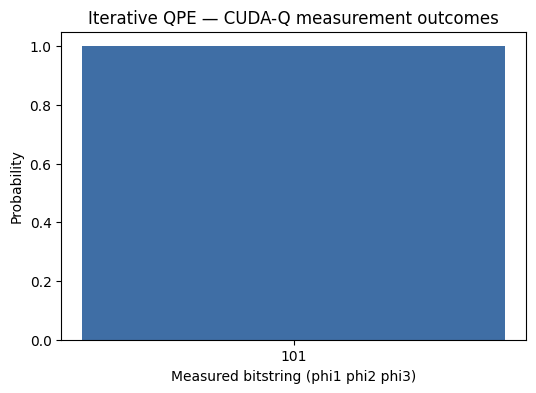

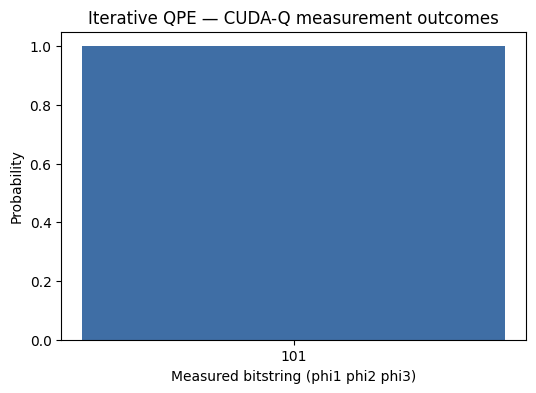

In [20]:
# Histogram (same style/axes as the Qiskit notebook's histogram)
fig2, ax2 = plt.subplots(figsize=(6, 4))
labels = list(reordered_counts.keys())
values = [reordered_counts[k] / SHOTS for k in labels]
ax2.bar(labels, values, color="#3f6ea5")
ax2.set_xlabel("Measured bitstring (phi1 phi2 phi3)")
ax2.set_ylabel("Probability")
ax2.set_ylim(0, 1.05)
ax2.set_title("Iterative QPE — CUDA-Q measurement outcomes")
fig2.savefig("iterative_qpe_cudaq_histogram.png", bbox_inches="tight", dpi=150)
fig2


In [24]:
# Resource counts
# The `cudaq.draw` function is currently experiencing an internal error with multiple `reset` calls.
# Commenting out the draw call to proceed.
# kernel_text = str(cudaq.draw(iqpe_kernel, LAMBDA))
# gate_lines = [ln for ln in kernel_text.splitlines() if ln.strip()]
# print("Kernel qubit count : 2 (anc, tgt)")
# print("Number of mid-circuit measurements: 3 (c0, c1, c2)")
# print("Approx. gate-diagram lines printed by cudaq.draw:", len(gate_lines))
# print()
# print(kernel_text)

# Provide a simplified output since cudaq.draw is not working
print("Kernel qubit count : 2 (anc, tgt)")
print("Number of mid-circuit measurements: 3 (c0, c1, c2)")
print("Note: The circuit diagram cannot be printed due to a known issue with cudaq.draw and multiple reset operations.")

Kernel qubit count : 2 (anc, tgt)
Number of mid-circuit measurements: 3 (c0, c1, c2)
Note: The circuit diagram cannot be printed due to a known issue with cudaq.draw and multiple reset operations.


## Convention notes (plain text)

- **Ordering fix applied**: yes — CUDA-Q's `explicit_measurements` output concatenates `c0 c1 c2` in temporal/kernel order (`phi_n ... phi_1`), which was explicitly reversed (own cell above) to `phi_1 phi_2 phi_3` (MSB->LSB) to match the Qiskit notebook's native convention.
- **Phase convention**: identical fixed correction constants (`-pi/2^m`) as the Qiskit notebook, applied via native Python `if` statements on measured booleans inside the `@cudaq.kernel` — this is CUDA-Q's supported mechanism for classical feedforward / dynamic circuits.


In [22]:
# Final cell: assign the (reordered, convention-matched) probability dict
CUDAQ_RESULT = probabilities
print("CUDAQ_RESULT =", CUDAQ_RESULT)


CUDAQ_RESULT = {'101': 1.0}


In [23]:
# Diff-check block (paste QISKIT_RESULT from the companion notebook here):
#
# QISKIT_RESULT = {"101": 1.0}   # <- paste from the Qiskit notebook's output
#
# all_keys = set(QISKIT_RESULT) | set(CUDAQ_RESULT)
# max_delta = max(abs(QISKIT_RESULT.get(k, 0.0) - CUDAQ_RESULT.get(k, 0.0)) for k in all_keys)
# print("Max probability delta:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q results do not match within tolerance!"
#
# Hand-computed expected result for sanity-checking (see cell above):
print("Hand-computed expected outcome: phi1,phi2,phi3 =", expected_phi_msb_first,
      "-> bitstring", "".join(map(str, expected_phi_msb_first)), "with probability ~1.0")


Hand-computed expected outcome: phi1,phi2,phi3 = [1, 0, 1] -> bitstring 101 with probability ~1.0
